In [1]:
!pip install trafilatura pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.9/151.9 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 837.9/837.9 kB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 13.6 MB/s eta 0:00:00


In [2]:
import pandas as pd
import trafilatura
from urllib.parse import urlparse
from urllib.robotparser import RobotFileParser

articles = pd.read_csv("sosc314_week3_data.csv")
articles = articles.copy()

USER_AGENT = "SOSC314-academic-project/1.0"

def robots_allows(url):
    parsed = urlparse(url)
    robots_url = f"{parsed.scheme}://{parsed.netloc}/robots.txt"

    parser = RobotFileParser()
    parser.set_url(robots_url)

    try:
        parser.read()
        return parser.can_fetch(USER_AGENT, url)
    except Exception:
        return False

def extract_article(url):
    if not robots_allows(url):
        return None

    downloaded = trafilatura.fetch_url(url)

    if downloaded is None:
        return None

    return trafilatura.extract(
        downloaded,
        include_comments=False,
        include_tables=False
    )

articles["text"] = articles["url"].apply(extract_article)
articles["word_count"] = articles["text"].fillna("").str.split().str.len()

print(articles[["outlet", "title_translated", "word_count"]])

                                               outlet  \
0                                       CNBC Mongolia   
1                                          Eagle News   
2                                           Ikon News   
3                                                iSee   
4                                     Government News   
5                                          Eagle News   
6                             State Great Khural News   
7                                           Urug News   
8                                          iToim News   
9                                           Ikon News   
10                                    E-Mongolia News   
11  Ministry of Digital Development, Innovation an...   
12                                       Khumuun News   
13                                           UBN News   
14                                          ICT Group   
15                                             iMedee   
16                             

In [3]:
for url in articles.loc[articles["word_count"] == 0, "url"]:
    print(url)
    print("Robots allowed:", robots_allows(url))

    downloaded = trafilatura.fetch_url(url)
    print("Downloaded:", downloaded is not None)

    if downloaded:
        extracted = trafilatura.extract(downloaded)
        print("Extracted:", extracted is not None)

    print()

https://eagle.mn/r/32iSXr3f8KF
Robots allowed: False


ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None


Downloaded: True
Extracted: False

https://isee.mn/n/94461
Robots allowed: False


ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None


Downloaded: True
Extracted: False

https://eagle.mn/r/f85WNWs55K3
Robots allowed: False


...

Downloaded: True
Extracted: False

https://urug.mn/158457/
Robots allowed: False


ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None


Downloaded: True
Extracted: False

https://e-mongolia.mn/news/n/8914
Robots allowed: False
Downloaded: True
Extracted: True

https://imedee.mn/n/94052
Robots allowed: False


ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None


Downloaded: True
Extracted: False



In [4]:
# Excluding the articles that were published before August 1st, 2026
articles["date"] = pd.to_datetime(articles["date"])

def date_during_selected_period(date):
    return date > pd.Timestamp("2026-08-01")

articles["during_selected_period"] = articles["date"].apply(
    date_during_selected_period
)

In [5]:
import re
import unicodedata

# Using unicode to normalize all the extracted text to make them lowercase

def clean_text(text):
    if not isinstance(text, str):
        return ""

    text = unicodedata.normalize("NFC", text)
    text = text.lower()
    text = re.sub(r"http\\S+|www\\.\\S+", " ", text)
    text = re.sub(r"\\s+", " ", text)

    return text.strip()

articles["clean_text"] = articles["text"].apply(clean_text)
articles["word_count_clean"] = (
    articles["clean_text"].str.split().str.len()
)

In [6]:
# Finding articles that are exact duplicates
import hashlib

articles["text_hash"] = articles["clean_text"].apply(
    lambda text: hashlib.sha256(text.encode()).hexdigest()
)

articles["exact_duplicate"] = articles.duplicated(
    "text_hash",
    keep=False
)

In [7]:
# Finding articles that mention Inner Mongolia
def mentions_inner_mongolia(text):
    keywords = [
        "inner mongolia",
        "inner mongolian",
        "өвөр монгол",
        "өвөрмонгол"
    ]

    text = str(text).lower()
    return any(keyword in text for keyword in keywords)

articles["mentions_inner_mongolia"] = articles["text"].apply(
    mentions_inner_mongolia
)

In [51]:
# Converting the boolean cells in the flag columns to strings because removing
# them without converting to strings first didn't work

boolean_columns = [
    "mentions_inner_mongolia",
    "during_selected_period",
    "exact_duplicate"
]

for column in boolean_columns:
    articles[column] = (
        articles[column]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("true")
    )

In [13]:
for column in [
    "mentions_inner_mongolia",
    "during_selected_period",
    "exact_duplicate"
]:
    print("\n", column)
    print(articles[column].value_counts(dropna=False))


 mentions_inner_mongolia
mentions_inner_mongolia
False    20
Name: count, dtype: int64

 during_selected_period
during_selected_period
True     16
False     4
Name: count, dtype: int64

 exact_duplicate
exact_duplicate
False    14
True      6
Name: count, dtype: int64


In [14]:
# Building a remove mask that flags the articles for removal

remove_mask = (
    articles["mentions_inner_mongolia"].eq(True) |
    articles["during_selected_period"].eq(False) |
    articles["exact_duplicate"].eq(True)
)

print("Articles flagged for removal:", remove_mask.sum())

articles.loc[
    remove_mask,
    [
        "title",
        "mentions_inner_mongolia",
        "during_selected_period",
        "exact_duplicate"
    ]
]

Articles flagged for removal: 9


,title,mentions_inner_mongolia,during_selected_period,exact_duplicate
1,"""Ногоон дата төв""-ийн төслөө танилцуулна",False,True,True
3,Ерөнхий сайд Н.Учрал Монгол Улсад ногоон дата ...,False,True,True
5,Монгол Улсад эрчим хүчний дата төвийг байгуулна,False,True,True
6,Хиймэл оюунд суурилсан Ногоон дата төв байгуулна,False,False,False
7,Төв аймагт хиймэл оюуны олон улсын дата Төв ба...,False,False,True
8,Хиймэл оюунд зориулсан үндэсний дата төв байгу...,False,False,False
9,"""Үндэсний дата төвийн ашиглалт, дүүргэлт 90 га...",False,False,False
10,COP17: МОНГОЛ УЛС “НОГООН ДАТА ТӨВ” БАЙГУУЛАХ ...,False,True,True
15,Ч.Номин: COP17-ын үеэр Монгол Улс AI ногоон да...,False,True,True


In [15]:
# Removing the articles

clean_articles = (
    articles.loc[~remove_mask]
    .copy()
    .reset_index(drop=True)
)

print("Original:", len(articles))
print("Removed:", remove_mask.sum())
print("Remaining:", len(clean_articles))

Original: 20
Removed: 9
Remaining: 11


In [16]:
clean_articles

,article_id,title,title_translated,outlet,date,url,text,word_count,during_selected_period,clean_text,word_count_clean,text_hash,exact_duplicate,mentions_inner_mongolia
0,A001,Монгол Улс “ногоон дата төв” байгуулна: Ямар б...,"Mongolia will build a ""green data center"": Wha...",CNBC Mongolia,2026-08-31,https://cnbc.mn/news/hcy5,Монгол Улс “ногоон дата төв” байгуулна: Ямар б...,89,True,монгол улс “ногоон дата төв” байгуулна: ямар б...,89,e309e4d9173eb692c7cbd52a5164600aec17a1944004ca...,False,False
1,A003,"Ногоон, хиймэл оюунд суурилсан дата төвийн хөг...",Ten memoranda of understanding were signed to ...,Ikon News,2026-08-26,https://ikon.mn/n/3pw3,"Ногоон, хиймэл оюунд суурилсан дата төвийн хөг...",456,True,"ногоон, хиймэл оюунд суурилсан дата төвийн хөг...",456,6796c60abc0ec07682d606147032f05cc3a93f7efa7fa0...,False,False
2,A005,COP17: МОНГОЛ УЛС “НОГООН ДАТА ТӨВ” БАЙГУУЛАХ ...,COP17: MONGOLIA HAS INTRODUCED THE INITIATIVE ...,Government News,2026-08-31,https://www.gov.mn/news/n/8914,🌍 НҮБ-ын Цөлжилттэй тэмцэх тухай конвенцын Тал...,240,True,🌍 нүб-ын цөлжилттэй тэмцэх тухай конвенцын тал...,240,04f8d142324704d2b5bc35f88cc371d2431c9ae9ac186f...,False,False
3,A012,Монгол Улс “Ногоон хиймэл оюун дата төвийн сан...,Mongolia unveiled the “Green AI Data Center In...,"Ministry of Digital Development, Innovation an...",2026-08-26,https://mddic.gov.mn/mn/%D0%BC%D0%BE%D0%BD%D0%...,НҮБ-ын Цөлжилттэй тэмцэх тухай конвенцын Талуу...,231,True,нүб-ын цөлжилттэй тэмцэх тухай конвенцын талуу...,231,536d2b1f057ecf00d746b221a66a5e0ab85ac1333cb5b7...,False,False
4,A013,COP17: Монгол Улс хиймэл оюунд суурилсан “Ного...,COP17: Mongolia to present its AI-powered “Gre...,Khumuun News,2026-08-18,https://www.khumuun.mn/a/1759,Улаанбаатар хотноо болж буй НҮБ-ын Цөлжилттэй ...,1521,True,улаанбаатар хотноо болж буй нүб-ын цөлжилттэй ...,1521,d77c4f80a94968fe29e5e0375dda9ed5ab3f7096af9e40...,False,False
5,A014,Н.Учрал: COP17 хурлын үеэр ногоон дата төв дээ...,N. Uchral: We expect to attract up to at least...,UBN News,2026-08-17,https://ubn.mn/p/100024,НҮБ-ийн цөлжилттэй тэмцэх тухай Конвенцын Талу...,71,True,нүб-ийн цөлжилттэй тэмцэх тухай конвенцын талу...,71,30045d561cdb5ade5172011af5af0e905b3baaafbe9eff...,False,False
6,A015,"МОНГОЛ УЛС “Ногоон, хиймэл оюун дата төвийн са...","MONGOLIA unveiled the ""Green AI Data Center In...",ICT Group,2026-09-02,https://www.ictgroup.mn/blog/2941,НҮБ-ын Цөлжилттэй тэмцэх тухай конвенцын Талуу...,270,True,нүб-ын цөлжилттэй тэмцэх тухай конвенцын талуу...,270,48d26723e0c179c6575f6c5333a42d14c7e8fca7a6e07b...,False,False
7,A017,"COP17: Ногоон дата төв, сэргээгдэх эрчим хүчни...",COP17: 10 Memoranda of Understanding Signed on...,CNBC Mongolia,2026-08-26,https://cnbc.mn/news/h21w3,"COP17: Ногоон дата төв, сэргээгдэх эрчим хүчни...",74,True,"cop17: ногоон дата төв, сэргээгдэх эрчим хүчни...",74,8f6c49cf40d7336214b8a6ea8c21a5938be14abe92a6e2...,False,False
8,A018,"COP17 | 34 шийдвэр баталж, Монгол Улсад 1.4 т...",COP17 | 34 decisions adopted; $1.4 billion pro...,UB.life,2026-08-28,https://ub.life/p/260828-kfzi9v,"Газрын доройтол, цөлжилт, гангийн асуудлаар дэ...",613,True,"газрын доройтол, цөлжилт, гангийн асуудлаар дэ...",613,f340d96c43739398e60d31297e1ad79ec3d0249798b603...,False,False
9,A019,COP17 хурлын үеэр Монгол Улс AI ногоон дата тө...,Mongolia will present its plans to build a gre...,Ikon News,2026-08-12,https://ikon.mn/n/3pk9,COP17 хурлын үеэр Монгол Улс AI ногоон дата тө...,177,True,cop17 хурлын үеэр монгол улс ai ногоон дата тө...,177,dc416d2a6f51c457e48f37ba007f6e1feb33cfa33d037c...,False,False


# Human-Coded Frame Assignments

In [17]:
clean_articles["orientation"] = ""
clean_articles["economic_frame"] = 0
clean_articles["technology_frame"] = 0
clean_articles["data_sovereignty_frame"] = 0
clean_articles["environmental_benefit_frame"] = 0
clean_articles["environmental_risk_frame"] = 0
clean_articles["energy_constraint_frame"] = 0
clean_articles["water_constraint_frame"] = 0
clean_articles["governance_frame"] = 0

In [18]:
clean_articles.loc[
    clean_articles["article_id"] == "A001",
    ["orientation", "economic_frame", "technology_frame", "energy_constraint_frame"]
] = ["Critical", 1, 1, 1]

In [19]:
clean_articles.loc[
    clean_articles["article_id"] == "A003",
    ["orientation", "economic_frame", "technology_frame"]
] = ["Supportive", 1, 1]

In [20]:
clean_articles.loc[
    clean_articles["article_id"] == "A005",
    ["orientation", "economic_frame"]
] = ["Supportive", 1]

In [21]:
clean_articles.loc[
    clean_articles["article_id"] == "A012",
    ["orientation", "economic_frame", "technology_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1]

In [22]:
clean_articles.loc[
    clean_articles["article_id"] == "A013",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame",
     "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame",
     "water_constraint_frame", "governance_frame"]
] = ["Balanced", 1, 1, 1, 1, 1, 1, 1, 1]

In [23]:
clean_articles.loc[
    clean_articles["article_id"] == "A014",
    ["orientation", "economic_frame"]
] = ["Balanced", 1]

In [24]:
clean_articles.loc[
    clean_articles["article_id"] == "A015",
    ["orientation", "economic_frame", "technology_frame",
     "environmental_benefit_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [25]:
clean_articles.loc[
    clean_articles["article_id"] == "A017",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame",
     "environmental_benefit_frame", "energy_constraint_frame",
     "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 1, 1]

In [26]:
clean_articles.loc[
    clean_articles["article_id"] == "A018",
    ["orientation", "economic_frame",
     "environmental_benefit_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1]

In [27]:
clean_articles.loc[
    clean_articles["article_id"] == "A019",
    ["orientation", "economic_frame", "governance_frame"]
] = ["Supportive", 1, 1]

In [29]:
clean_articles.loc[
    clean_articles["article_id"] == "A020",
    ["orientation", "economic_frame", "technology_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1]

Analyzing the frequency of various frames in the articles

In [31]:
frame_columns = [
    "economic_frame",
    "technology_frame",
    "data_sovereignty_frame",
    "environmental_benefit_frame",
    "environmental_risk_frame",
    "energy_constraint_frame",
    "water_constraint_frame",
    "governance_frame"
]

In [33]:
frame_counts = clean_articles[frame_columns].sum().sort_values(ascending = False)

frame_percentages = (clean_articles[frame_columns].mean() * 100).sort_values(ascending = False)

frame_summary = pd.DataFrame({"article_count": frame_counts,
                              "percentage": frame_percentages.round(1)})

frame_summary

,article_count,percentage
economic_frame,11,100.0
technology_frame,7,63.6
governance_frame,7,63.6
environmental_benefit_frame,4,36.4
energy_constraint_frame,3,27.3
data_sovereignty_frame,2,18.2
environmental_risk_frame,1,9.1
water_constraint_frame,1,9.1


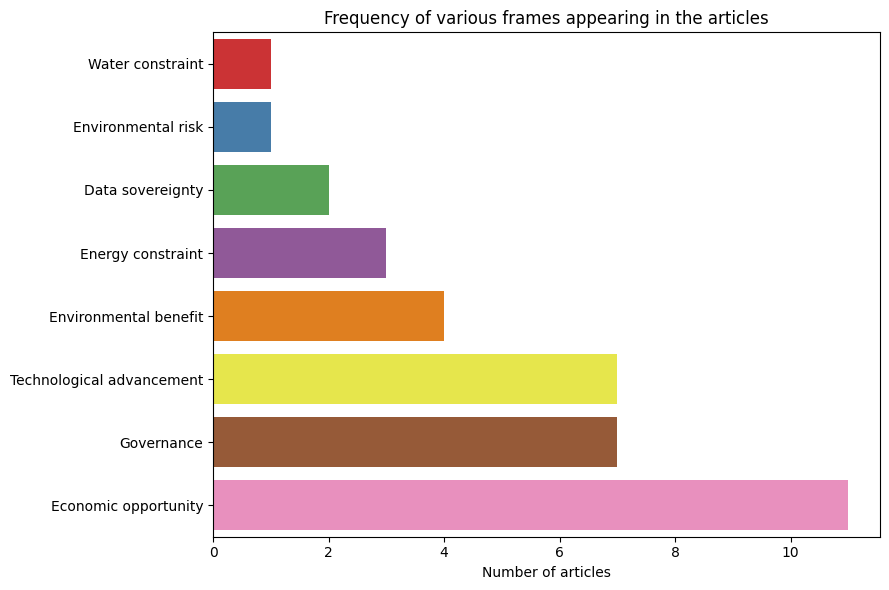

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

frame_names = {
    "economic_frame": "Economic opportunity",
    "technology_frame": "Technological advancement",
    "data_sovereignty_frame": "Data sovereignty",
    "environmental_benefit_frame": "Environmental benefit",
    "environmental_risk_frame": "Environmental risk",
    "energy_constraint_frame": "Energy constraint",
    "water_constraint_frame": "Water constraint",
    "governance_frame": "Governance"
}

frame_plot = (clean_articles[frame_columns]
              .sum()
              .rename(index = frame_names)
              .sort_values())

plt.figure(figsize=(9, 6))

sns.barplot(
    x=frame_plot.values,
    y=frame_plot.index,
    hue=frame_plot.index,
    palette="Set1",
    legend=False
)

plt.xlabel("Number of articles")
plt.ylabel("")
plt.title("Frequency of various frames appearing in the articles")
plt.tight_layout()
plt.show()

# Bag-of-Words

In [55]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

mongolian_stopwords = {
    "нь", "ын", "ийн", "ыг", "ийг", "д", "т", "аас", "ээс",
    "оос", "өөс", "тай", "тэй", "той", "болон", "ба", "бөгөөд",
    "юм", "байна", "байгаа", "гэсэн", "гэж"
}

vectorizer = CountVectorizer(
    binary=True,
    ngram_range=(1, 1),
    lowercase=True,
    stop_words=list(mongolian_stopwords)
)

matrix = vectorizer.fit_transform(
    clean_articles["clean_text"]
)

bag_of_words_dataframe = pd.DataFrame(
    matrix.toarray(),
    columns=vectorizer.get_feature_names_out(),
    index=clean_articles["article_id"]
)

bag_of_words_dataframe

,02,03,08,10,100,110,12,13,130,15,...,өөрийг,өөрийн,өөрчлөгдөж,өөрчлөлт,өөрчлөлтийг,өөрчлөлтийн,өөрчлөлттэй,өөрчлөхөөс,өөрөө,өөрөөр
article_id,,,,,,,,,,,,,,,,,,,,,
A001,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A002,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A003,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A004,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A005,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A006,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A007,1,1,0,0,0,0,1,1,1,1,...,0,0,0,1,0,0,0,1,0,0
A008,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A009,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [56]:
bag_of_words_frequency = bag_of_words_dataframe.sum().sort_values(ascending=False)

bag_of_words_frequency.head(20)

,0
дата,14
сайд,13
ногоон,13
монгол,13
улсын,12
олон,12
төв,12
хөрөнгө,12
хиймэл,11
эрчим,10


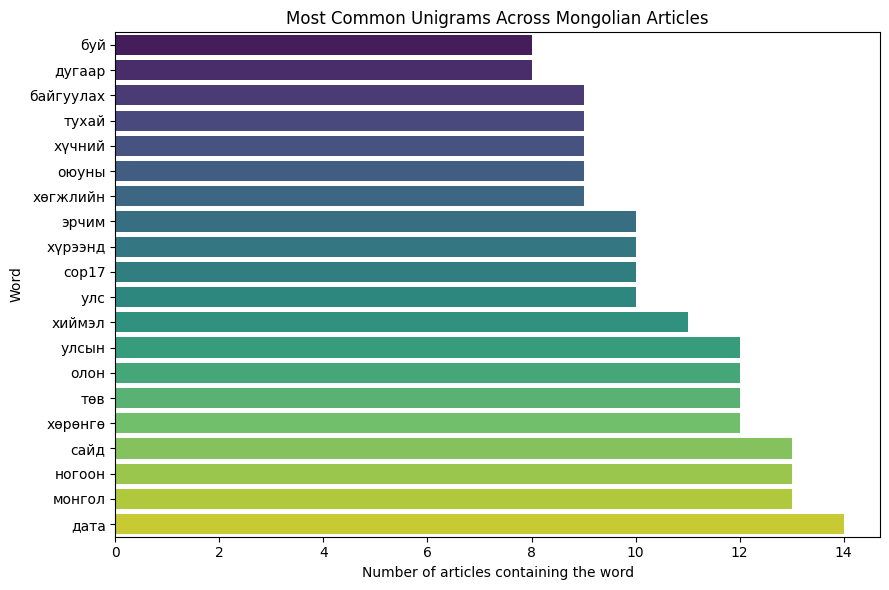

In [57]:
top_words = bag_of_words_frequency.head(20).sort_values()

plt.figure(figsize=(9, 6))

sns.barplot(
    x=top_words.values,
    y=top_words.index,
    hue=top_words.index,
    palette="viridis",
    legend=False
)

plt.xlabel("Number of articles containing the word")
plt.ylabel("Word")
plt.title("Most Common Unigrams Across Articles")
plt.tight_layout()
plt.show()

# Tf-idf

In [58]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    lowercase=True,
    min_df=1,
    stop_words=list(mongolian_stopwords)
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    clean_articles["clean_text"]
)

tfidf_dataframe = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out(),
    index=clean_articles["article_id"]
)

tfidf_dataframe

,02,02 үйлдвэрийн,03,03 багцын,03 ны,08,08 сарын,10,10 ажил,10 гбит,...,өөрчлөлтийн сайд,өөрчлөлттэй,өөрчлөлттэй холбоотой,өөрчлөхөөс,өөрчлөхөөс бусад,өөрөө,өөрөө монголын,өөрөө эцсийн,өөрөөр,өөрөөр хэлбэл
article_id,,,,,,,,,,,,,,,,,,,,,
A001,0.000000,0.000000,0.000000,0.000000,0.000000,0.081969,0.081969,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A002,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A003,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.064752,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A004,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A005,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A006,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A007,0.024624,0.024624,0.049248,0.024624,0.024624,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.024624,0.024624,0.000000,0.000000,0.000000,0.000000,0.000000
A008,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A009,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.149470,0.074121,0.074121,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [59]:
mean_tfidf = tfidf_dataframe.mean().sort_values(ascending=False)

mean_tfidf.head(20)

,0
дата,0.056132
монгол,0.048257
улсын,0.045465
төв,0.042457
эрчим,0.041923
ногоон,0.041557
хиймэл,0.040613
хөрөнгө,0.038143
дата төв,0.036354
дэд,0.030545


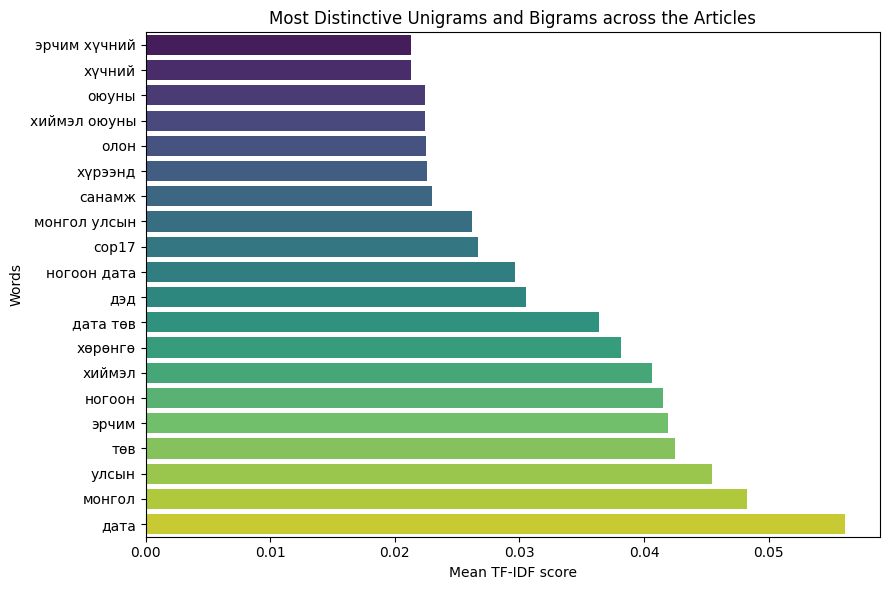

In [60]:
top_tfidf = mean_tfidf.head(20).sort_values()

plt.figure(figsize=(9, 6))

sns.barplot(
    x=top_tfidf.values,
    y=top_tfidf.index,
    hue=top_tfidf.index,
    palette="viridis",
    legend=False
)

plt.xlabel("Mean TF-IDF score")
plt.ylabel("Words")
plt.title("Most Distinctive Unigrams and Bigrams across the Articles")
plt.tight_layout()
plt.show()

# Translated terms

In [61]:
translations = {
    # TF-IDF and shared terms
    "хүчин": "Capacity",
    "сэргээгдэх": "Renewable",
    "улс": "Country",
    "технологийн": "Technology",
    "олон": "Many",
    "хүрээнд": "Within the framework",
    "санамж": "Memorandum",
    "монгол улсын": "Mongolia’s",
    "cop17": "COP17",
    "ногоон дата": "Green data",
    "дэд": "Infrastructure / sub-",
    "дата төв": "Data center",
    "хөрөнгө": "Investment / capital",
    "хиймэл": "Artificial",
    "ногоон": "Green",
    "төв": "Center",
    "улсын": "Country’s",
    "монгол": "Mongolia",
    "эрчим": "Energy",
    "дата": "Data",

    # Bag-of-words terms
    "оюуны": "Intelligence",
    "талуудын": "Parties’",
    "хамтын": "Cooperative",
    "оруулалт": "Input / contribution",
    "тухай": "About",
    "хөгжлийн": "Development",
    "сайд": "Minister"
}

In [62]:
def translate_label(term):
    english = translations.get(term, term)
    return f"{term} — {english}"

# Both graphs in one

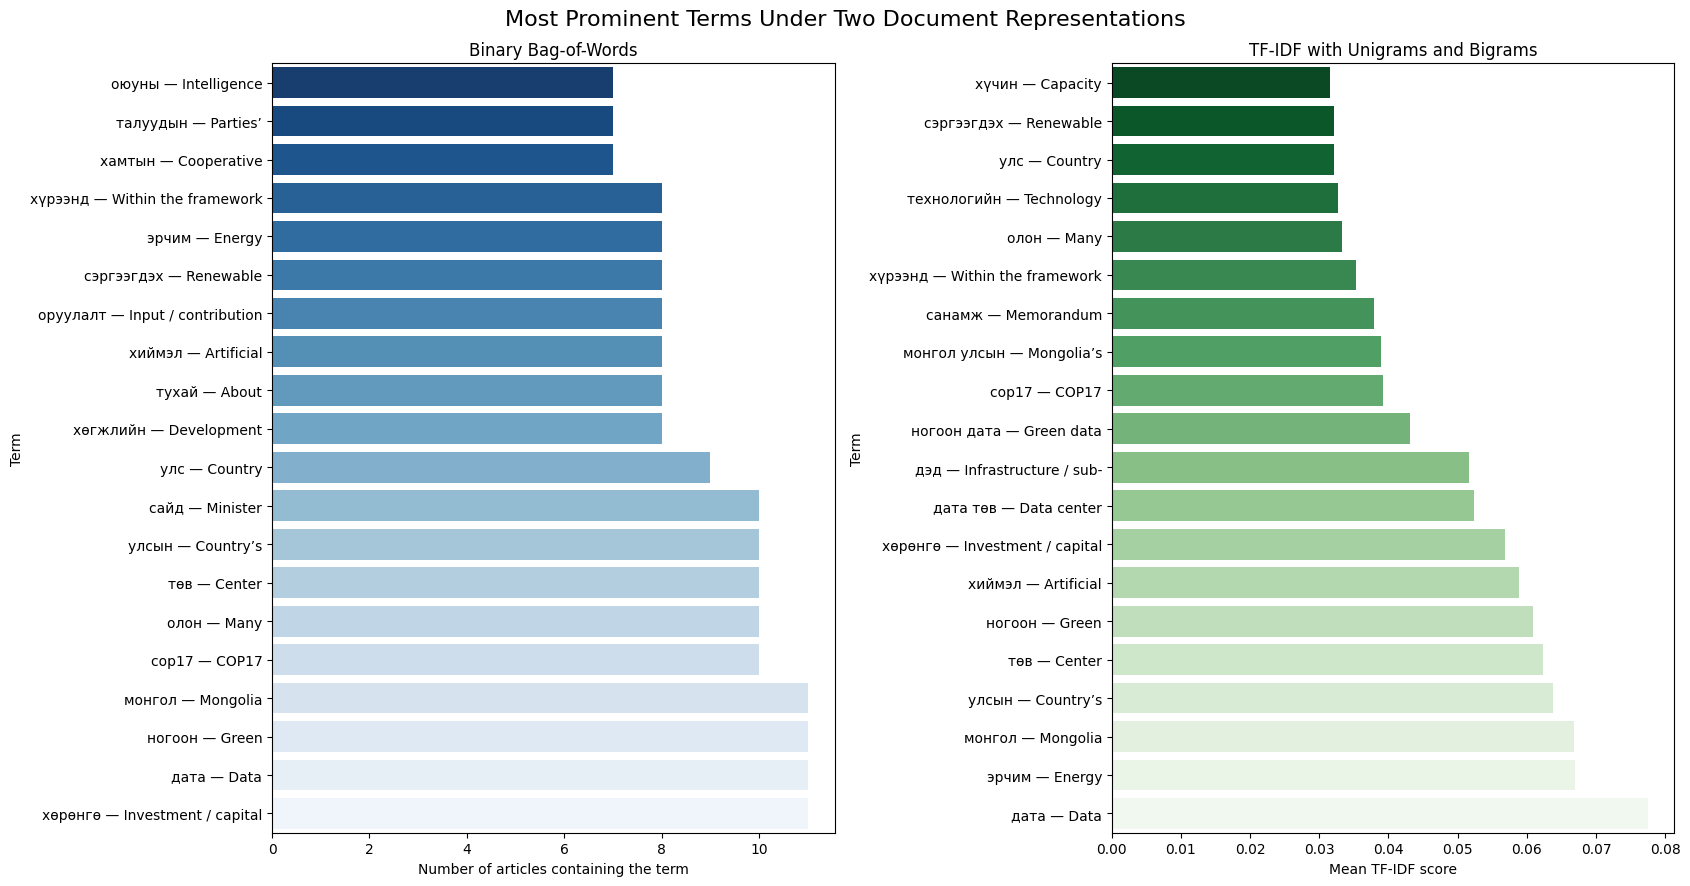

In [43]:
# Select the top 20 and translate labels
top_bag_of_words = bag_of_words_frequency.head(20).sort_values()
top_tfidf = mean_tfidf.head(20).sort_values()

top_bag_of_words.index = [translate_label(term) for term in top_bag_of_words.index]
top_tfidf.index = [translate_label(term) for term in top_tfidf.index]

fig, axes = plt.subplots(1, 2, figsize=(17, 9))

# Bag-of-words
sns.barplot(
    x=top_bag_of_words.values,
    y=top_bag_of_words.index,
    hue=top_bag_of_words.index,
    palette="Blues_r",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Binary Bag-of-Words")
axes[0].set_xlabel("Number of articles containing the top word")
axes[0].set_ylabel("Words")

# TF-IDF
sns.barplot(
    x=top_tfidf.values,
    y=top_tfidf.index,
    hue=top_tfidf.index,
    palette="Greens_r",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("TF-IDF with Unigrams and Bigrams")
axes[1].set_xlabel("Mean TF-IDF score")
axes[1].set_ylabel("Words")

fig.suptitle(
    "Most Prominent Words Under Two Document Representations",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    "bow_tfidf_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Creating frame dictionaries using stems and phrases from the top words found from the Bag-of-Words and Tf-idf

*   \w* permits different endings.
*   \s+ permits one or more spaces between words.

In [44]:
frame_dictionary = {
    "economic_proxy": [
        r"хөрөнгө\s+оруулалт\w*"
    ],

    "technology_proxy": [
        r"хиймэл\s+оюун\w*",
        r"технолог\w*",
        r"дэд\s+бүтэц",
        r"өндөр\s+хүчин\s+чадал\w*"
    ],

    "environmental_benefit_proxy": [
        r"сэргээгдэх\s+эрчим\s+хүч\w*"
    ],

    "governance_proxy": [
        r"санамж\s+бичиг\w*",
        r"хамтын\s+ажиллагаа"
    ]
}

In [45]:
import re

# Creating a function that finds any of the patterns in the frame dictionary

def contains_any_pattern(text, patterns):
    text = str(text).lower()

    return int(any(
        re.search(pattern, text, flags=re.IGNORECASE)
        for pattern in patterns
    ))

for frame, patterns in frame_dictionary.items():
    clean_articles[frame] = clean_articles["clean_text"].apply(
        lambda text: contains_any_pattern(text, patterns)
    )

In [46]:
# Adding the proxy columns to the clean_articles sheet

proxy_columns = list(frame_dictionary.keys())

clean_articles[
    ["article_id"] + proxy_columns
]

,article_id,economic_proxy,technology_proxy,environmental_benefit_proxy,governance_proxy
0,A001,1,1,1,0
1,A003,1,1,1,1
2,A005,1,1,1,0
3,A012,1,1,1,1
4,A013,1,1,1,1
5,A014,1,0,0,0
6,A015,1,1,0,1
7,A017,1,1,1,1
8,A018,1,1,1,1
9,A019,1,1,0,0


In [48]:
# Counting how many articles has the frames that were built from
# the dictionary proxy and estimating their percentage
proxy_frame_summary = pd.DataFrame({
    "article_count": clean_articles[proxy_columns].sum(),
    "percentage": clean_articles[proxy_columns].mean().mul(100).round(1)
})

proxy_frame_summary

,article_count,percentage
economic_proxy,11,100.0
technology_proxy,9,81.8
environmental_benefit_proxy,7,63.6
governance_proxy,7,63.6


In [49]:
# Comparing the frame findings from human-coded assignment and dictionary-based frame proxy

comparison = pd.DataFrame({
    "human_coded_economic": clean_articles["economic_frame"],
    "keyword_economic": clean_articles["economic_proxy"],

    "human_coded_technology": clean_articles["technology_frame"],
    "keyword_technology": clean_articles["technology_proxy"],

    "human_coded_environmental_benefit":
        clean_articles["environmental_benefit_frame"],
    "keyword_environmental_benefit":
        clean_articles["environmental_benefit_proxy"],

    "human_coded_governance": clean_articles["governance_frame"],
    "keyword_governance": clean_articles["governance_proxy"]
})

comparison

,manual_economic,keyword_economic,manual_technology,keyword_technology,manual_environmental_benefit,keyword_environmental_benefit,manual_governance,keyword_governance
0,1,1,1,1,0,1,0,0
1,1,1,1,1,0,1,0,1
2,1,1,0,1,0,1,0,0
3,1,1,1,1,0,1,1,1
4,1,1,1,1,1,1,1,1
5,1,1,0,0,0,0,0,0
6,1,1,1,1,1,0,1,1
7,1,1,1,1,1,1,1,1
8,1,1,0,1,1,1,1,1
9,1,1,0,1,0,0,1,0


In [50]:
# Comparing the frequency of frames appearing in the articles based on both presentations

count_comparison = pd.DataFrame({
    "Human-coded": [
        clean_articles["economic_frame"].sum(),
        clean_articles["technology_frame"].sum(),
        clean_articles["environmental_benefit_frame"].sum(),
        clean_articles["governance_frame"].sum()
    ],

    "Top-term proxies": [
        clean_articles["economic_proxy"].sum(),
        clean_articles["technology_proxy"].sum(),
        clean_articles["environmental_benefit_proxy"].sum(),
        clean_articles["governance_proxy"].sum()
    ]
}, index=[
    "Economic opportunity",
    "Technological advancement",
    "Environmental benefit",
    "Governance"
])

count_comparison

,Manual coding,Top-term proxies
Economic opportunity,11,11
Technological advancement,7,9
Environmental benefit,4,7
Governance,7,7
